In [3]:
from IPython.display import Image

Всем, кто пользуется нейросетями для генерации текста и/или кода, знакома проблема галлюцинаций языковых моделей (когда они с уверенным видом выдают ответ, не соответствующий действительности). Тесно связано с ней явление jailbreak - когда инструкцией удается заставить модель обходить вшитые инструкции безопасности и выдавать неприличные или вредоносные ответы.

К сожалению, эти свойства являются отражением самой архитектуры трансформеров. На вход модель получает предыдущий текст (так называемый промпт от пользователя плюс текст, сгенерированный ранее), а на выходе - Output Probabilities, вероятности следующего слова/токена из словаря $V$. Возникает естественный вопрос: если это не удается предотвратить - можно ли  детектировать?

На митапе Сбера "ИИ: наука в действии" https://vkvideo.ru/live-229792778_456239040 теме галлюцинаций было посвящено два доклада (00:49:00 и 4:51:00). Также разберем близкую к ним статью, анализирующую механизм jailbreak.




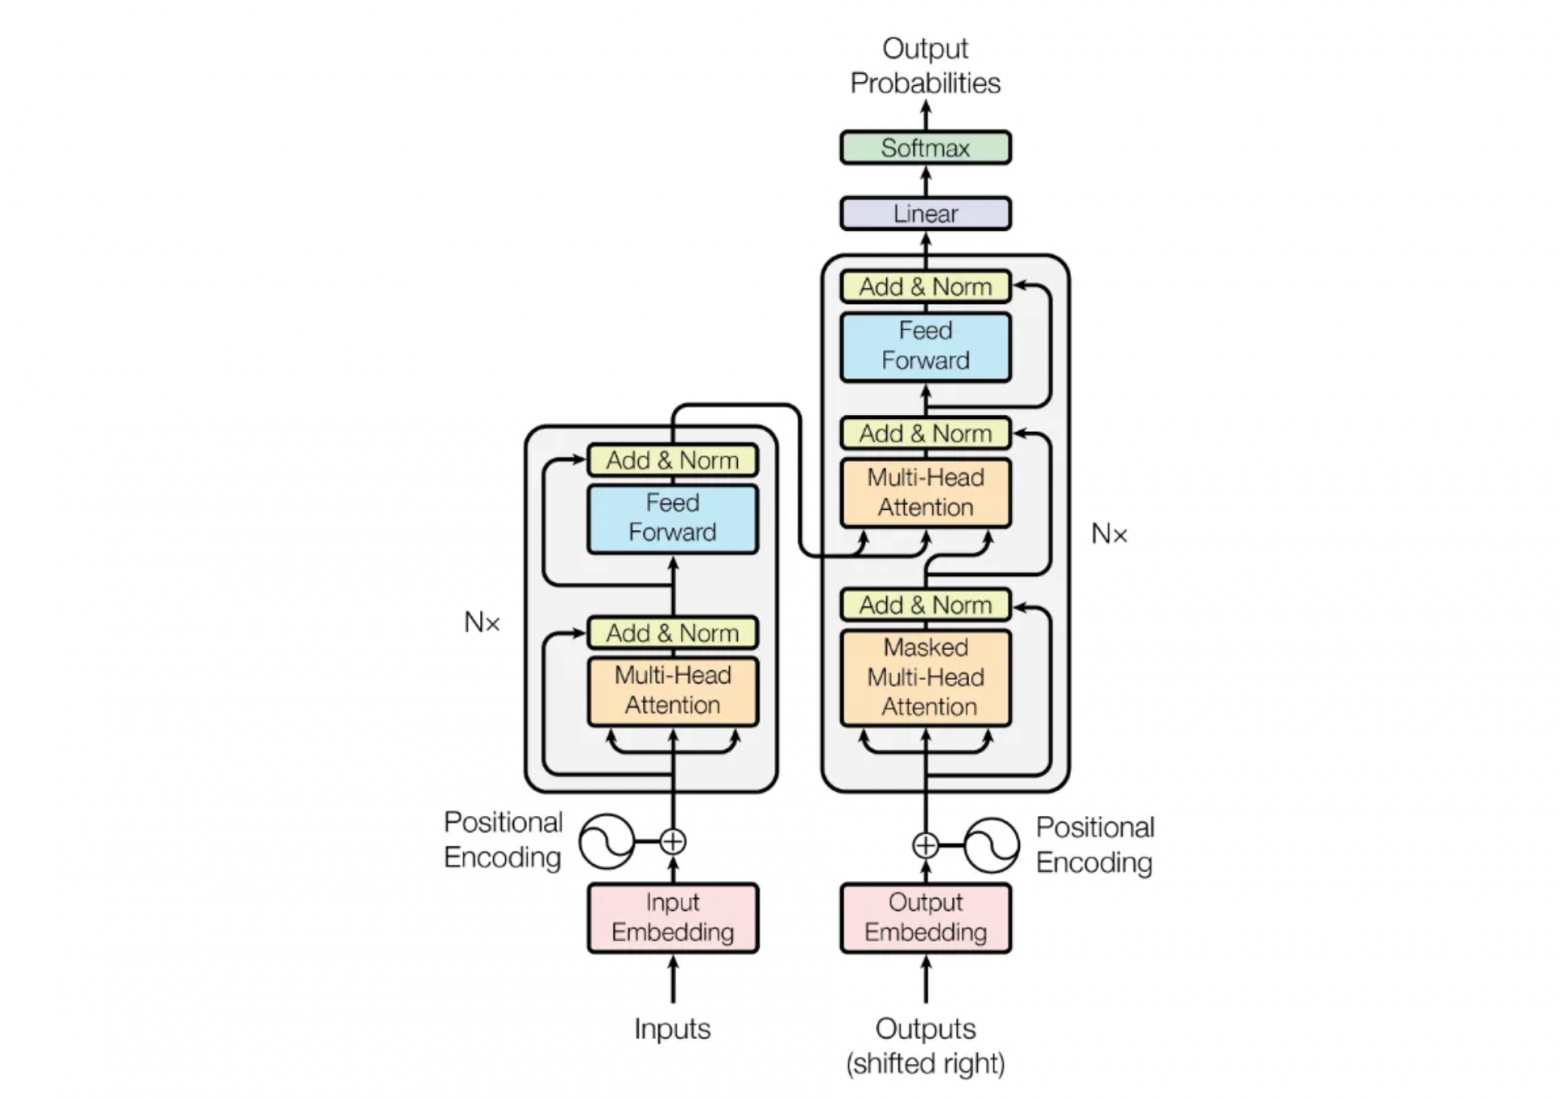

In [5]:
Image('Trans.png', width=600, height=150 )

# Содержание

1. What Intermediate Layers Know: Detecting Jailbreaks from Entropy Dynamics  (Jun 2026) - Статья с ECML PKDD 2026 за авторством Sofiia Nikolenko, Michele Papucci, Mina Rezaei, and Shireen Kudukkil Manchinga https://arxiv.org/abs/2606.25182  

2. Детекция галлюцинаций в ответах LLM - Юлия Беликова, Senior researcher (Sber AI Lab) - https://vkvideo.ru/live-229792778_456239040 00:49:00

3. Можно ли доверять ИИ?

Алексей Зайцев, Доцент (Skoltech), руководитель группы (блок «Риски» Сбер) - https://vkvideo.ru/live-229792778_456239040 4:51:00

Обзор результатов лаборатории

# 1. What Intermediate Layers Know: Detecting Jailbreaks from Entropy Dynamics

**Центральная гипотеза** заключается в том, что джейлбрейк-промты не просто изменяют общий уровень неопределенности, а вызывают структурированную динамику изменений предиктивной энтропии по мере развертывания токенов. Энтропия в физике и теории информации для вектора вероятностей $p = (p_1,..., p_n)$ является мерой неуверенности и считается как $H(p) = -\sum_{i} p_i \log p_i$, или с помощью вариаций этой формулы.

**Признаки (feature engineering):**

Модель M имеет L слоёв. Мы работаем в режиме White-box, то есть имеем прямой доступ ко всем слоям модели. Значит, для промпта с токенами $x = (x_1, \dots, x_T)$ мы можем посчитать скрытое состояние на позиции t и слое $\ell$, обозначим его $h_t^{(\ell)} \in \mathbb{R}^d$, где $d$ - размерность эмбеддинга (длина вектора, кодирующего токен $x_t$, этот эмбеддинг от слоя к слою трансформера модифицируется, но длину не меняет). Цель — построить детекционный скор s(x) - одномерную-скалярную функцию - который разделяет джейлбрейк (y=1) и безопасные (y=0) промпты. Используем только промежуточные активации $h_t^{(\ell)}$ за один прямой проход. Чтобы не утонуть в вычислениях, фиксируем набор $K$ слоев $\mathcal{L} = \{\ell_1, \dots, \ell_K\}$:
$$\phi : \{ H^{(\ell)}(x) : \ell \in \mathcal{L} \} \mapsto s(x),$$
где функции $H$ строятся следующим образом:

Для получения распределения по словарю на произвольном слое $\ell$ применяется техника **logit lens**: скрытое состояние проецируется в пространство словаря напрямую через финальный слой (который расположен на выходе и преобразует матрицу эмбеддингов текста $x$ в словарь $V$), минуя оставшиеся слои. Таким образом, мы можем посчитать энтропию токена на позиции t и слое \ell:
$$H_t^{(\ell)}(x) = -\sum_{v \in V} p^{(\ell)}(v \mid x_{<t}) \log p^{(\ell)}(v \mid x_{<t}).$$
Траектория $H^{(\ell)}(x) = (H_1^{(\ell)}, \dots, H_{T-1}^{(\ell)})$ служит основой для признаков: статических vs. динамических.

• Статические: среднее, медиана, максимум, минимум, стандартное отклонение траектории — отражают величину неопределенности.

• Динамические трендовые: направление изменения неопределенности, в частности ранговый тренд Кендалла (\tau), который количественно оценивает монотонность эволюции энтропии по позициям токенов.

**Эксперименты:**

Для каждого промпта $x$ из датасета джейлбрейков и безопасных запросов мы получаем набор статических и динамических признаков $s_j(x)$. Для оценки качества разделения для каждого признака используется метрика ROCAUC.  

В работе исследовались модели Llama-3.1-8B, Qwen3-8B и Gemma-7B.

**Выводы**

• Джейлбрейки детектируются без обучения — по внутренней динамике энтропии замороженной LLM за один прямой проход.

• Ключевой сигнал — не уровень, а динамика неопределенности: вредоносные промпты дают структурно согласованный тренд энтропии по токенам на промежуточных слоях, тогда как статические признаки (средняя энтропия, дисперсия) нестабильны. Ранговые трендовые: Kendall τ, Spearman ρ и монотонность дают высокую AUROC и кросс-модельную согласованность (std ≈ 0.02), в отличие от статических признаков.

• Сигнал сосредоточен в средней части сети (~50–85% глубины), а на финальном слое резко деградирует — финальные слои подавляют или реорганизуют этот сигнал.

• **Главный итог**: внутренние представления LLM содержат устойчивый, архитектурно переносимый сигнал вредоносности, который можно извлекать простыми ранговыми статистиками энтропийной траектории без обучения.

# 2. Детекция галлюцинаций в ответах LLM

https://arxiv.org/abs/2608.00033 SIRIN: A Unified Toolkit for Detecting Contextual Hallucinations in Retrieval-Augmented and Memory-Grounded LLM Systems (Jul 2026)

Галлюцинации могут противоречить общей модели мира, либо же контексту, который мы подаем модели (LLM забыла или забила на инструкции и документы, которые мы ей подаем). Фреймворк SIRIN https://github.com/sb-ai-lab/SIRIN объединяет три подхода для детекции галлюцинаций:

1. Probing (зондирование представлений)
 
Это white-box-подход, напоминающий предыдущую статью: он анализирует внутренние сигналы генератора. Поверх замороженных скрытых состояний (hidden states) обучаются лёгкие классификаторы — линейные, табличные или с attention-пулингом, опционально с контрастивными целями. Коллеги из Сбера разработали множество фичей для анализа, таких как соотношения attention на разных слоях, топологические признаки над графами внимания и т д.
 
2. Judge (судья)
 
Это black-box-подход: для проверки используется вторая модель, которая анализирует только наблюдаемые входы и выходы. Проводится семантическая верификация текста с помощью энкодеров, декодеров или API-моделей, включая проверки фактичности в стиле NLI и alignment. Судья ищет противоречия между предоставленными доказательствами и ответом
 
3. Uncertainty Estimation (оценка неопределённости)
 
Этот подход оценивает генерации по паттернам уверенности модели. SIRIN оборачивает библиотеку LM-Polygraph и объединяет 38 различных оценок (энтропия, перплексия, SAR, P(True) и др.) в единый калиброванный балл. Идея в том, что неуверенная генерация (например, «плоское» распределение вероятностей) с большей вероятностью может быть галлюцинацией.

Другие темы, которые были затронуты в докладе:

• Универсальной модели нет

• Важно правильно размечать и составлять датасеты, на которых мы тестируем наш фреймворк.

# 3. Можно ли доверять ИИ?

Доклад представляет собой краткий обзор некоторых результатов лаборатории. Этот доклад тесно связан с предыдущи (что можно предположить, обращая внимание на коллектив авторов работ) и чуть более подробно объясняет, как строятся графы внимания - по весам в матрице скалярных произведений Attention.

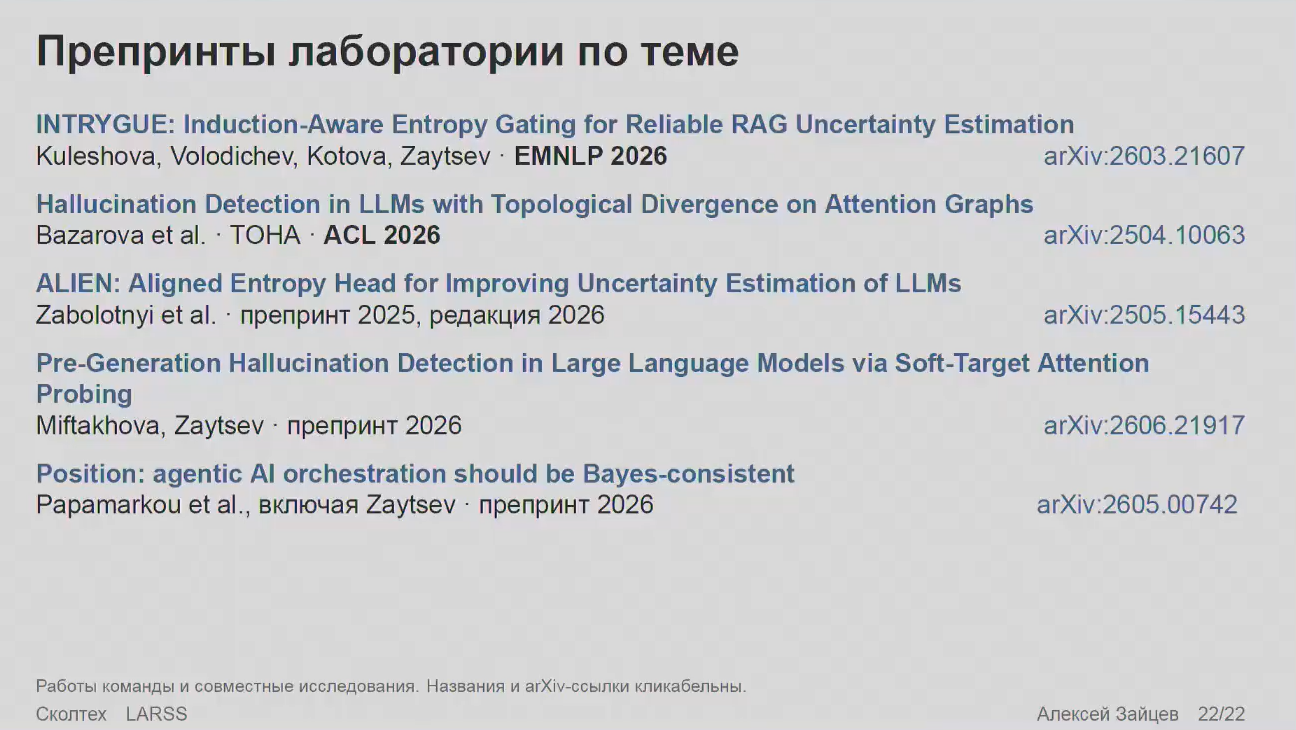

In [4]:
Image('Ref.png', width=600, height=150 )

В частности, описаны

• Induction head - обнаружены блоки Attention, которые отвечают за продолжение ранее встречавшегося шаблона. В них можно наблюдать attention sink - концентрацию весов в одном токене. Это позволило построить метрику SinkRate.

• Энтропийные нейроны (https://arxiv.org/abs/2603.21607 INTRYGUE: Induction-Aware Entropy Gating for Reliable RAG Uncertainty Estimation) - нейроны с аномально большими весами, ломающими нормировку очередного слоя. Это помогло модифицировать предыдущую метрику. 

# Итог

В настоящее время вероятностная природа больших языковых моделей серьезно ограничивает их применимость и автоматизацию. Даже небольшая галлюцинация или сбой в механизме может вылиться в огромные убытки. Поэтому исследования механизма внимания - очень широкое поле для деятельности. И при этом высокая согласованность с контекстом и разметкой может не гарантировать корректности - если в исходных данных у нас были ошибки.